# Calculate single perturbation score per variant

We want one overall edgotyping score to make variant-level hit calls. Here we explore several strategies for this:

- call the variant "perturbed" if any edge is perturbed
- compute the fraction of perturbed edges and find some way to calibrate this score
- calculate the Euclidean distance between profiles and find some way to calibrate this score

# Automated

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
import os

In [2]:
outputs_dir = "../3_outputs/sqY2H"
meta_outputs = "../../../1_allele_collection/3_outputs"

In [3]:
# Calculate Euclidean distance for each variant relative to it's wildtype reference
orf_profiles = [f for f in os.listdir(f"{outputs_dir}/edgotype_profiles/auto_summed") if "_auto_summed" in f]

zero_col = "0"
perturbed_thresh = 0.5 # edge called "perturbed" if >= 50% decrease compared to wt reference
orf_distances = []

wt_thresh = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

for orf in orf_profiles:
    profiles = pl.read_csv(f"{outputs_dir}/edgotype_profiles/auto_summed/{orf}")
    
    # filter out edges where the WT could not be measured
    profiles = profiles.filter(~pl.col("0").is_null())

    db_orf_id = orf.replace("orf_id_", "")
    db_orf_id = db_orf_id.replace("_auto_summed.csv", "")

    columns = [col for col in profiles.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profiles_filled = profiles.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profiles_filled[col] - profiles_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())

        # Cosine similarity
        wt = profiles_filled.select(zero_col).to_numpy()
        var = profiles_filled.select(col).to_numpy()

        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim

        # calculate frac perturbed
        wt_pass = []
        per_edges = []
        for thresh in wt_thresh:
            filt_wt = profiles.filter(pl.col("0") > thresh)
            wt_pass.append(filt_wt.shape[0])
            per_edges.append(filt_wt.filter((pl.col(col)/pl.col("0")) <= perturbed_thresh).shape[0])            

        distance_rows.append({
            "db_orf_id": db_orf_id,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            # "cosine_distance": cos_dist,
            "num_edges": profiles.shape[0],
            "num_zero_wt": profiles.filter(pl.col("0") == 0).shape[0],
            "num_per_0.0": per_edges[0],
            "num_per_0.1": per_edges[1],
            "num_per_0.2": per_edges[2],
            "num_per_0.3": per_edges[3],
            "num_per_0.4": per_edges[4],
            "num_per_0.5": per_edges[5],
            "num_edge_0.0": wt_pass[0],
            "num_edge_0.1": wt_pass[1],
            "num_edge_0.2": wt_pass[2],
            "num_edge_0.3": wt_pass[3],
            "num_edge_0.4": wt_pass[4],
            "num_edge_0.5": wt_pass[5],
            "frac_per_0.0": per_edges[0]/wt_pass[0] if wt_pass[0] != 0 else None,
            "frac_per_0.1": per_edges[1]/wt_pass[1] if wt_pass[1] != 0 else None,
            "frac_per_0.2": per_edges[2]/wt_pass[2] if wt_pass[2] != 0 else None,
            "frac_per_0.3": per_edges[3]/wt_pass[3] if wt_pass[3] != 0 else None,
            "frac_per_0.4": per_edges[4]/wt_pass[4] if wt_pass[4] != 0 else None,
            "frac_per_0.5": per_edges[5]/wt_pass[5] if wt_pass[5] != 0 else None
        })


    result_profiles = pl.DataFrame(distance_rows)
    orf_distances.append(result_profiles)

# concatentate and normalize wrt dimensionality
orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)


In [4]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,num_edges,num_zero_wt,num_per_0.0,num_per_0.1,num_per_0.2,num_per_0.3,num_per_0.4,num_per_0.5,num_edge_0.0,num_edge_0.1,num_edge_0.2,num_edge_0.3,num_edge_0.4,num_edge_0.5,frac_per_0.0,frac_per_0.1,frac_per_0.2,frac_per_0.3,frac_per_0.4,frac_per_0.5,normalized_euclid_distance
str,str,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""9866""","""216927""",2800.120564,2,0,1,1,1,1,1,1,2,2,2,2,2,2,0.5,0.5,0.5,0.5,0.5,0.5,1979.984239
"""9866""","""216928""",3443.1497,2,0,1,1,1,1,1,1,2,2,2,2,2,2,0.5,0.5,0.5,0.5,0.5,0.5,2434.674502
"""5442""","""215414""",5037.093899,4,0,0,0,0,0,0,0,4,4,4,4,4,4,0.0,0.0,0.0,0.0,0.0,0.0,2518.54695
"""513""","""213754""",3738.170548,3,0,1,1,1,1,1,1,3,3,3,3,3,3,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,2158.233772
"""513""","""213753""",1195.479709,3,0,0,0,0,0,0,0,3,3,3,3,3,3,0.0,0.0,0.0,0.0,0.0,0.0,690.210532
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""3732""","""201256""",330.216994,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,330.216994
"""3732""","""201252""",185.779019,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,185.779019
"""3732""","""201258""",476.473297,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,476.473297


In [5]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances = orf_distances.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
orf_distances.write_csv(f"{outputs_dir}/5_variant_perturbation_scores_automated_summed.csv")

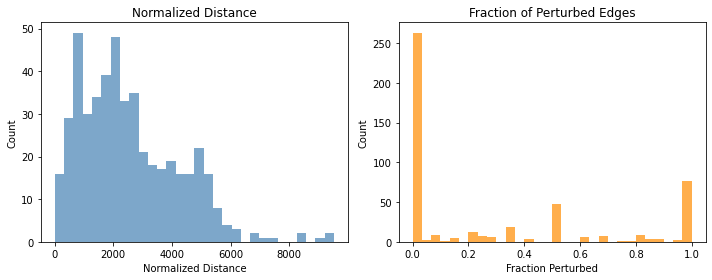

In [6]:

x = orf_distances['normalized_euclid_distance']
y = orf_distances['frac_per_0.3']

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].hist(x, bins=30, color='steelblue', alpha=0.7)
axs[0].set_title("Normalized Distance")
axs[0].set_xlabel("Normalized Distance")
axs[0].set_ylabel("Count")

axs[1].hist(y, bins=30, color='darkorange', alpha=0.7)
axs[1].set_title("Fraction of Perturbed Edges")
axs[1].set_xlabel("Fraction Perturbed")
axs[1].set_ylabel("Count")

plt.tight_layout()
plt.show()